# Four-Omniwheel Robot: Dynamic, Motor-Limited Control Testbed

**Purpose:** provide a reproducible simulation for testing three-axis PID, LQR, MPC, and future constrained/robust controllers against a plant with chassis dynamics, wheel rotational dynamics, a DC motor model, actuator nonlinearities, and nonlinear wheel-ground friction.

This is a **research simulation baseline**, not a validated digital twin. The motor/electrical parameters and wheel geometry are explicit and editable, but should be calibrated against the selected robot before interpreting numerical results as hardware predictions.

## System definition

The system is a planar rigid chassis supported by four independently actuated omniwheels. Each wheel has a rotational state, motor electrical state (modeled quasi-steadily), and a wheel-ground contact interaction. The chassis has three planar degrees of freedom: world position \((X,Y)\) and heading \(\theta\); its body-frame velocity is \((v_x,v_y,\omega)\). The four wheel angular speeds are \(\dot\phi_i\), for \(i=1,\ldots,4\).

The model is **control-oriented**: it preserves the dominant couplings and hard nonlinearities needed for controller comparison, while omitting detailed roller geometry, armature-current transients, battery sag, and thermal behavior. It should be read as a clearly specified approximate plant, not as a claim that every physical effect is represented.

### Main state and signal groups

| Group | Variables | Meaning |
|---|---|---|
| Chassis pose | \((X,Y,\theta)\) | Position and heading in the world frame |
| Chassis velocity | \((v_x,v_y,\omega)\) | Translational and angular velocity in the body frame |
| Wheel state | \(\dot\phi_i\) | Each wheel's angular speed |
| Motor telemetry | \(V_i,i_i,\tau_{m,i}\) | Applied voltage, armature current, and motor torque |
| Contact telemetry | \(s_i,F_i,F_{\max,i}\) | Projected slip speed, traction force, and friction limit |
| Controller signals | \(\xi_{cmd},\dot{\boldsymbol\phi}_{cmd}\) | Requested body twist and wheel-speed references |

The controller does not directly set chassis velocity. It requests motion; the inverse-kinematics map, wheel-speed servo, DC motor limits, wheel inertia, and friction-limited contact determine the resulting motion.


## 1. Modeling assumptions and sign conventions

### Chassis and wheel geometry
- Planar rigid chassis with four independently driven omniwheels. The same Jacobian defines inverse kinematics and the projected rolling velocity at each contact.
- Front and rear wheel mounting angles are separate configuration values: `FRONT_WHEEL_ANGLE_DEG = 30°` and `REAR_WHEEL_ANGLE_DEG = 45°` by default. The front pair uses `+/- alpha_front`; the rear pair uses `pi +/- alpha_rear`. Edit both only from the configuration cell at the beginning. **Verify angle and sign conventions against CAD/hardware**; round-trip tests establish internal consistency, not physical correctness.
- Wheel contact transmits force only along each wheel's active rolling direction. The perpendicular direction is treated as ideally free due to the omni rollers.

### Coupled dynamics
- Chassis translation and yaw use Newton–Euler equations, including body-frame rotational coupling.
- Each wheel has rotational inertia. Motor torque accelerates the wheel and is reduced by the contact reaction torque and viscous bearing loss.
- The motor is a simple DC motor with quasi-steady armature current: back-EMF, winding resistance, torque constant, current cutoff, voltage deadband, voltage saturation, and a hard speed limit. Armature inductance is neglected.
- A PI wheel-speed servo converts wheel-speed requests into voltage requests. This is a separate actuator layer; controllers still command body twist through inverse kinematics.

### Nonlinear contact / friction
- Projected slip speed is `wheel_radius * wheel_angular_speed - contact_velocity_along_rolling_direction`.
- A compliant contact law maps slip speed to traction force, then caps it at a friction limit. The friction coefficient transitions smoothly from static-like `mu_s` near zero slip to kinetic `mu_k` during sliding. This regularized law avoids a discontinuous sign switch but is still a simplified tire/roller contact model.
- Normal load is approximated as `mass*g/4` per wheel. No load transfer, roller-level dynamics, lateral scrub, or detailed LuGre/Dahl bristle model is included.
- Friction disturbances are sampled per wheel at initialization and held fixed for a trial. Sensor noise is added to observations, never to the true pose.

### Interpretation
The plant deliberately preserves hard nonlinearities and actuator/contact coupling so advanced controllers can be stress-tested. It is not a full electrical model (no armature inductance, battery sag, PWM switching, thermal limits, or gearbox backlash). Treat numerical results as comparative evidence on this specified model, not as real-robot predictions until parameters and signs are identified experimentally.


## 1.1 Simulation architecture and data flow

The simulation is organized as a **controller-independent plant plus a replaceable controller**. The baseline controller is a three-axis pose PID; future controllers should use the same experiment runner and the same plant parameters so the comparison remains fair.

```text
Reference pose (x*, y*, theta*)
              |
              v
     Pose measurement model <--- true chassis pose
              |
              v
   Three-axis PID (x, y, heading error)
              |
              v
      Body-twist command [vx, vy, omega]
              |
              v
       Inverse wheel kinematics
              |
              v
     Wheel-speed reference (4 wheels)
              |
              v
  Wheel-speed PI servo / voltage request
              |
              v
 DC motor: deadband, voltage/current limits,
       back-EMF, speed cutoff, torque
              |
              v
    Wheel rotational dynamics <------+
              |                       |
              v                       | contact reaction torque
  Wheel-ground slip and friction -----+
              |
              v
  Contact forces and moments on chassis
              |
              v
    Chassis Newton-Euler dynamics
              |
              v
  Integrate state; log pose, slip, force,
  current, voltage, torque and saturation
```

### One simulation time step

At time \(t_k\), the runner samples the reference pose and the observation model. The controller computes a body-twist command from pose error. Inverse kinematics converts that twist to four wheel-speed targets. The actuator layer turns wheel-speed error into voltage, then the motor model computes current and torque subject to its nonlinear limits. Using the current wheel and chassis velocities, the contact model computes slip and friction-limited forces. Those same contact forces (i) accelerate the chassis and (ii) exert reaction torque on the wheels. The integrator advances the wheel and chassis states to \(t_{k+1}\), and the runner logs the result.

The order is explicit and matters numerically: contact forces are evaluated from the state at the beginning of the step, then the states are advanced. Consequently, the chosen time step must be checked for convergence. The same random seed should be reused for paired controller trials; friction variation is fixed per wheel per trial, while sensor noise is sampled each observation.

### Separation of responsibilities

- **Controller:** turns measured pose error into a requested body twist. It should not bypass the motor or friction constraints.
- **Kinematics:** maps body twist to wheel-speed targets using one shared geometry/Jacobian definition.
- **Actuator model:** models wheel-speed servo behavior and the voltage/current/torque/speed limits.
- **Plant physics:** integrates wheel rotation and chassis motion with contact forces coupled between them.
- **Experiment runner:** controls timing, seeds, metrics, plots, and logging. A new controller should plug into this interface without rewriting the plant.



In [1]:
# Imports and the single configuration block: edit tunable numeric values here first.
# Geometry, plant, actuator, friction, controller, and experiment settings are grouped below.
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Tuple, Dict, Any

np.set_printoptions(precision=4, suppress=True)

# --- Chassis geometry and physical parameters (SI units) ---
MASS_KG = 2.7
YAW_INERTIA_KG_M2 = 0.0074
BASE_RADIUS_M = 0.06
WHEEL_RADIUS_M = 0.03
FRONT_WHEEL_ANGLE_DEG = 30.0
REAR_WHEEL_ANGLE_DEG = 45.0
WHEEL_INERTIA_KG_M2 = 2.0e-4
WHEEL_VISCOUS_DRAG_NM_S_RAD = 2.0e-4
MAX_WHEEL_SPEED_RAD_S = 150.0
GRAVITY_M_S2 = 9.81

# --- DC motor and wheel-speed servo ---
MOTOR_BUS_VOLTAGE_V = 12.0
MOTOR_RESISTANCE_OHM = 0.6
MOTOR_TORQUE_CONSTANT_NM_A = 0.1
MOTOR_BACK_EMF_V_S_RAD = MOTOR_BUS_VOLTAGE_V / MAX_WHEEL_SPEED_RAD_S
MOTOR_CURRENT_LIMIT_A = 20.0
MOTOR_VOLTAGE_DEADBAND_V = 0.15
WHEEL_SPEED_PI_KP = 0.30
WHEEL_SPEED_PI_KI = 2.0
WHEEL_SPEED_PI_INTEGRAL_LIMIT = 8.0

# --- Wheel-ground contact model ---
MU_STATIC = 0.8
MU_KINETIC = 0.5
SLIP_STIFFNESS_N_PER_M_S = 180.0
FRICTION_TRANSITION_SPEED_M_S = 0.08
ENABLE_FRICTION_DEFAULT = True
ENABLE_STATIC_TO_KINETIC_TRANSITION_DEFAULT = True

# --- Disturbances / measurement model ---
FRICTION_NOISE_STD = 0.05
DISTURBED_FRICTION_NOISE_STD = 0.07
MEASUREMENT_NOISE_XY_STD_M = 0.002
MEASUREMENT_NOISE_HEADING_STD_RAD = np.deg2rad(0.25)

# --- Three-axis pose PID gains and output/integral limits (x, y, heading) ---
POSE_PID_KP = (3.5, 3.5, 2.0)
POSE_PID_KI = (0.1, 0.1, 0.05)
POSE_PID_KD = (0.4, 0.4, 0.2)
POSE_PID_BODY_LIMITS = (1.5, 1.5, 3.0)
POSE_PID_INTEGRAL_LIMITS = (1.5, 1.5, 1.5)

# --- Default experiment settings ---
SIM_DT_S = 0.001
REFERENCE_PERIOD_S = 12.0
REFERENCE_AMPLITUDE_M = 1.0
NOMINAL_RANDOM_SEED = 11
COMPARISON_RANDOM_SEED = 23
ROBUSTNESS_SEEDS = tuple(range(10))

# --- Numerical validation tolerances and plot layout ---
KINEMATICS_ATOL = 1e-9
REFERENCE_CHECK_DT_S = 1e-5
REFERENCE_DERIVATIVE_ATOL = 2e-5
PLOT_FIGSIZE_WIDE = (14, 10)
PLOT_FIGSIZE_SLIP = (12, 4)


## 2. Parameters and state

All plant parameters live in `RobotParameters`, while the instantaneous physical state and telemetry live in `RobotState`. Keeping them separate makes it possible to change controller gains without accidentally changing the plant, and to hold the plant fixed for controlled algorithm comparisons.

### DC motor equations and actuator nonlinearities

For each wheel motor, the quasi-steady armature equation is
\[
V_i = R_m i_i + K_e\dot\phi_i,
\qquad
 i_i = \operatorname{clip}\!\left(\frac{V_i-K_e\dot\phi_i}{R_m},-I_{\max},I_{\max}\right),
\]
with motor torque
\[
\tau_{m,i}=K_t i_i.
\]
Here \(V_i\) is the applied motor voltage, \(R_m\) is winding resistance, \(K_e\) is the back-EMF constant, \(i_i\) is current, and \(K_t\) is the torque constant. Back-EMF opposes applied voltage as speed rises, so available current and torque naturally fall with speed. The code also applies a voltage deadband, bus-voltage saturation, a hard current limit, and a hard wheel-speed cutoff. These are intentionally nonsmooth nonlinearities that controllers must tolerate.

The speed servo is a separate actuator interface: wheel-speed error drives a PI law that requests voltage. Its integral state is clamped and uses conditional anti-windup when voltage saturation and error would push farther into saturation. This inner servo is **not** the trajectory controller; the high-level baseline remains three-axis pose PID only. The present electrical approximation assumes current responds instantaneously to voltage and back-EMF; it does not integrate an inductive current state.

The nominal stall-current and stall-torque references follow from the model:
\[
I_{stall}=\frac{V_{bus}}{R_m},\qquad
\tau_{stall}=K_t I_{stall}.
\]
These are consistency checks, not independent parameters. Confirm whether motor constants and inertia are referred to the motor shaft or wheel/gearbox output shaft; mixing shaft conventions produces incorrect torque and speed limits.

### Parameter groups

- **Geometry/inertia:** chassis mass and yaw inertia, wheel positions, wheel radius, and effective wheel/gearbox rotational inertia.
- **Motor/servo:** bus voltage, winding resistance, \(K_t\), \(K_e\), current and speed cutoffs, deadband, and wheel-speed PI gains.
- **Contact:** static-like and kinetic friction coefficients, slip-force slope, transition speed, gravity, and assumed normal load.
- **Experiment conditions:** friction variation, measurement noise, timestep, and random seed.

The default values are illustrative. They make the simulation executable but are not a substitute for identifying the actual robot's motor constants, gearing, inertia, friction, and sensor quality.


In [2]:
# Centralized physical/model parameters. Keep tunable values in the configuration cell above.
@dataclass
class RobotParameters:
    # Chassis and geometry
    mass: float = MASS_KG                    # kg
    inertia: float = YAW_INERTIA_KG_M2              # kg m^2, yaw inertia
    R_base: float = BASE_RADIUS_M                 # m, center-to-wheel distance
    wheel_radius: float = WHEEL_RADIUS_M           # m
    alpha_front: float = np.deg2rad(FRONT_WHEEL_ANGLE_DEG)
    alpha_rear: float = np.deg2rad(REAR_WHEEL_ANGLE_DEG)

    # Wheel and drivetrain
    wheel_inertia: float = WHEEL_INERTIA_KG_M2        # kg m^2, effective wheel + reflected gearbox inertia
    wheel_viscous_drag: float = WHEEL_VISCOUS_DRAG_NM_S_RAD   # N m s/rad
    max_wheel_speed: float = MAX_WHEEL_SPEED_RAD_S       # rad/s, hard mechanical/software cutoff

    # Simple DC motor (per wheel; values are illustrative starting points)
    motor_voltage: float = MOTOR_BUS_VOLTAGE_V          # V, bus magnitude
    motor_resistance: float = MOTOR_RESISTANCE_OHM        # ohm; gives 20 A stall current at 12 V
    motor_Kt: float = MOTOR_TORQUE_CONSTANT_NM_A                # N m/A
    motor_Ke: float = MOTOR_BACK_EMF_V_S_RAD       # V s/rad; nominal free speed ~= 150 rad/s
    motor_current_limit: float = MOTOR_CURRENT_LIMIT_A    # A, hard current cutoff
    motor_voltage_deadband: float = MOTOR_VOLTAGE_DEADBAND_V # V, controller/driver dead zone
    speed_kp: float = WHEEL_SPEED_PI_KP               # V per (rad/s) wheel speed error
    speed_ki: float = WHEEL_SPEED_PI_KI                # V per (rad/s*s), wheel speed PI integral
    speed_integral_limit: float = WHEEL_SPEED_PI_INTEGRAL_LIMIT    # integral error clamp, rad

    # Contact-model switches
    enable_friction: bool = ENABLE_FRICTION_DEFAULT  # master switch; normally keep True
    enable_static_to_kinetic_transition: bool = ENABLE_STATIC_TO_KINETIC_TRANSITION_DEFAULT  # False holds mu at mu_static

    # Regularized wheel-ground contact
    mu_static: float = MU_STATIC
    mu_kinetic: float = MU_KINETIC
    slip_stiffness: float = SLIP_STIFFNESS_N_PER_M_S         # N per (m/s) of projected slip speed
    friction_transition_speed: float = FRICTION_TRANSITION_SPEED_M_S # m/s, static-to-kinetic transition scale
    gravity: float = GRAVITY_M_S2

    # Trial disturbances / sensing
    enable_disturbances: bool = False
    friction_noise_std: float = FRICTION_NOISE_STD      # per-wheel coefficient variation
    measurement_noise_xy: float = MEASUREMENT_NOISE_XY_STD_M   # m standard deviation
    measurement_noise_heading: float = MEASUREMENT_NOISE_HEADING_STD_RAD

    @property
    def tau_stall(self):
        return self.motor_Kt * self.motor_voltage / self.motor_resistance

    def validate(self):
        positive = [self.mass, self.inertia, self.R_base, self.wheel_radius,
                    self.wheel_inertia, self.max_wheel_speed, self.motor_voltage,
                    self.motor_resistance, self.motor_Kt, self.motor_Ke,
                    self.motor_current_limit, self.slip_stiffness,
                    self.friction_transition_speed, self.gravity]
        if any(v <= 0 for v in positive):
            raise ValueError("Physical parameters and limits must be positive.")
        if self.mu_static <= 0 or self.mu_kinetic <= 0 or self.mu_static < self.mu_kinetic:
            raise ValueError("Require mu_static >= mu_kinetic > 0 for this friction transition.")
        if min(self.friction_noise_std, self.measurement_noise_xy,
               self.measurement_noise_heading, self.motor_voltage_deadband) < 0:
            raise ValueError("Noise and deadband values must be non-negative.")

# State and telemetry arrays use the fixed wheel order returned by wheel_geometry().
@dataclass
class RobotState:
    pose: np.ndarray              # ground-truth global [x, y, theta]
    body_velocity: np.ndarray     # body-frame [vx, vy, yaw_rate]
    wheel_speeds: np.ndarray      # actual wheel angular speed [rad/s]
    motor_torques: np.ndarray     # actual electromagnetic torque [N m]
    motor_currents: np.ndarray    # armature current [A]
    motor_voltages: np.ndarray   # applied voltage [V]
    ground_forces: np.ndarray     # signed scalar force along each wheel's rolling direction [N]
    slip_speeds: np.ndarray       # projected wheel-ground slip speed [m/s]
    friction_limits: np.ndarray   # per-wheel traction force cap [N]

def wrap_angle(angle):
    """Wrap angles to [-pi, pi] so heading errors take the shortest direction."""
    return np.arctan2(np.sin(angle), np.cos(angle))

def rotation_world_from_body(theta):
    """Rotation matrix mapping a vector expressed in body axes into world axes."""
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])


## 3. Shared wheel geometry and kinematics

The wheel geometry is represented by the position \(r_i=[r_{ix},r_{iy}]^T\) of each contact point relative to the chassis center and a unit vector \(u_i=[u_{ix},u_{iy}]^T\) along the wheel's active rolling direction. This is the direction in which the model transmits traction force. The perpendicular direction is treated as ideally free because the wheels are omniwheels.

For body-frame chassis twist \(\xi=[v_x,v_y,\omega]^T\), the velocity at contact point \(i\) is
\[
v_{c,i}=\begin{bmatrix}v_x-\omega r_{iy}\\v_y+\omega r_{ix}\end{bmatrix}.
\]
Projecting onto the rolling direction and equating ideal rolling speed gives
\[
R\dot\phi_i = u_i^T v_{c,i},
\qquad
J_i=\frac{1}{R}[u_{ix},u_{iy},-u_{ix}r_{iy}+u_{iy}r_{ix}].
\]
Stacking all four rows yields \(\dot{\boldsymbol\phi}=J\xi\). Inverse kinematics computes wheel-speed references from a requested body twist. Forward kinematics estimates twist from wheel speeds using a least-squares solution because four wheel measurements estimate three body-motion variables.

The same geometry is used in the contact model to calculate projected ground velocity. Reusing one Jacobian convention avoids a common modeling bug: using one yaw lever arm for inverse kinematics and a different lever arm for force/moment calculations. Round-trip tests establish algebraic consistency, but the wheel-angle signs still need checking against CAD or low-speed hardware tests.


In [3]:
# Purpose: Implement or test the subsystem described immediately above.
def wheel_geometry(params: RobotParameters) -> Tuple[np.ndarray, np.ndarray]:
    """Return wheel positions (4x2) and active rolling directions (4x2)."""
    # Wheel order is front-left, front-right, rear-right, rear-left.
    # Front and rear mounting angles are independent configuration parameters.
    L = params.R_base / np.sqrt(2.0)
    positions = np.array([[ L,  L], [ L, -L], [-L, -L], [-L,  L]], dtype=float)
    af, ab = params.alpha_front, params.alpha_rear
    # Each row is a unit vector along that wheel’s active rolling direction.
    # Front pair uses +/- alpha_front; rear pair uses pi +/- alpha_rear.
    directions = np.array([
        [np.cos(af), np.sin(af)],
        [np.cos(-af), np.sin(-af)],
        [np.cos(np.pi - ab), np.sin(np.pi - ab)],
        [np.cos(np.pi + ab), np.sin(np.pi + ab)],
    ], dtype=float)
    return positions, directions

def wheel_jacobian(params: RobotParameters) -> np.ndarray:
    """Map body twist [vx, vy, yaw_rate] to wheel angular speeds."""
    positions, directions = wheel_geometry(params)
    J = np.zeros((4, 3), dtype=float)
    for i, ((rx, ry), (ux, uy)) in enumerate(zip(positions, directions)):
        J[i] = np.array([ux, uy, -ux * ry + uy * rx]) / params.wheel_radius
    return J

def inverse_kinematics(body_twist: np.ndarray, params: RobotParameters) -> np.ndarray:
    """Compute four wheel-speed targets from one body-frame twist."""
    body_twist = np.asarray(body_twist, dtype=float)
    if body_twist.shape != (3,):
        raise ValueError("body_twist must have shape (3,).")
    return wheel_jacobian(params) @ body_twist

def forward_kinematics(wheel_speeds: np.ndarray, params: RobotParameters) -> np.ndarray:
    """Estimate body twist from four wheel speeds using least squares."""
    wheel_speeds = np.asarray(wheel_speeds, dtype=float)
    if wheel_speeds.shape != (4,):
        raise ValueError("wheel_speeds must have shape (4,).")
    return np.linalg.lstsq(wheel_jacobian(params), wheel_speeds, rcond=None)[0]

params_nominal = RobotParameters()
params_nominal.validate()
J = wheel_jacobian(params_nominal)
print("Wheel Jacobian (4x3):\n", J)
print("Jacobian rank:", np.linalg.matrix_rank(J))
assert np.linalg.matrix_rank(J) == 3, "Geometry must span all three planar body motions."
assert not np.isclose(params_nominal.alpha_front, params_nominal.alpha_rear), \
    "Front and rear wheel mounting angles should be independently configured."
print(f"Front wheel angle: {FRONT_WHEEL_ANGLE_DEG:.1f} deg; rear wheel angle: {REAR_WHEEL_ANGLE_DEG:.1f} deg.")

Wheel Jacobian (4x3):
 [[ 28.8675  16.6667  -0.5176]
 [ 28.8675 -16.6667   0.5176]
 [-23.5702  23.5702  -2.    ]
 [-23.5702 -23.5702   2.    ]]
Jacobian rank: 3
Front wheel angle: 30.0 deg; rear wheel angle: 45.0 deg.


## 4. Kinematics validation tests

These tests check the forward/inverse mapping round trip for forward, lateral, rotational, and combined motion. They establish internal mathematical consistency, but do not prove the assumed wheel directions match a physical chassis. Confirm the geometry from CAD or a low-speed hardware test before interpreting this as a real robot model.

In [4]:
# Purpose: run the validation or analysis described in the Markdown section immediately above.
def validate_kinematics(params: RobotParameters, atol=KINEMATICS_ATOL):
    twists = [
        np.array([0.25, 0.0, 0.0]),
        np.array([0.0, 0.20, 0.0]),
        np.array([0.0, 0.0, 0.8]),
        np.array([0.15, -0.07, 0.35]),
    ]
    for twist in twists:
        reconstructed = forward_kinematics(inverse_kinematics(twist, params), params)
        assert np.allclose(reconstructed, twist, atol=atol, rtol=1e-8), (twist, reconstructed)
    return True

assert validate_kinematics(params_nominal)
print("PASS: forward/lateral/yaw/combined kinematics round-trip tests.")

PASS: forward/lateral/yaw/combined kinematics round-trip tests.


## 5. Figure-8 reference, three-axis PID baseline, and command path to the wheels

The desired planar path is parameterized by
\[
x^*(t)=A\sin(\nu t),\qquad y^*(t)=\frac{A}{2}\sin(2\nu t),\qquad \nu=\frac{2\pi}{T}.
\]
The code computes analytic reference derivatives for checking and plotting, but the controller does **not** use reference velocity or acceleration. The desired heading is the path-tangent angle \(\theta^*=\operatorname{atan2}(\dot y^*,\dot x^*)\); its angular rate is reference telemetry only.

### Three-axis pose PID (no feedforward)

The controller forms world-frame position error \(e_p^w=p^*-p\), rotates it into the robot frame, and wraps the heading difference into \([-\pi,\pi]\):
\[
e_p^b=R(\theta)^T(p^*-p),\qquad e_\theta=\operatorname{wrap}(\theta^*-\theta).
\]
For each axis, it combines proportional, integral, and derivative error terms:
\[
u_j=K_{p,j}e_j+K_{i,j}\int e_j\,dt+K_{d,j}\frac{de_j}{dt},\qquad j\in\{x,y,\theta\}.
\]
The resulting three values are interpreted as a desired **body twist** \([v_x^{cmd},v_y^{cmd},\omega^{cmd}]^T\), not as motor current, voltage, torque, or wheel speed. The integral is clamped, the derivative is based on error change, and the body-twist outputs are clipped to configured limits. The controller does not receive reference velocity/acceleration as feedforward, so it must generate motion from pose error alone and can lag a moving reference.

### How the PID motion command becomes four wheel-speed targets

The conversion happens **after** `ThreeAxisPIDController.compute()` returns; it is performed by the shared experiment runner, not inside the PID class:

1. **Pose error → body motion command.** PID returns \([v_x^{cmd},v_y^{cmd},\omega^{cmd}]\) in the robot/body frame. Linear components are in m/s and yaw rate is in rad/s.
2. **Body twist → wheel speeds (inverse kinematics).** `inverse_kinematics(body_cmd, params)` applies the wheel Jacobian \(\boldsymbol\omega^{cmd}=J(\text{geometry})\,\boldsymbol\xi^{cmd}\), where \(\boldsymbol\xi^{cmd}=[v_x^{cmd},v_y^{cmd},\omega^{cmd}]^T\). Each row of \(J\) uses that wheel's rolling direction, wheel radius, and moment arm. The result is four target wheel angular speeds in rad/s. Rotation contributes differently to each wheel according to its contact-point geometry; it is not simply the same yaw term added to every wheel.
3. **Wheel-speed target → motor voltage/current/torque.** The plant's inner wheel-speed PI compares each target with that wheel's actual angular speed. Its output is a voltage request, limited by the bus voltage and a small voltage deadband. The model estimates current from voltage minus back-EMF divided by winding resistance, clamps current, and converts current to electromagnetic torque using \(\tau=K_t i\). Anti-windup prevents the PI integrator from continuing to push hard into voltage saturation.
4. **Torque → wheel acceleration and ground traction.** Wheel torque is opposed by contact reaction torque and viscous drag. Wheel acceleration is integrated using the wheel's effective rotational inertia. The ground-contact model computes each wheel's projected slip from wheel-rim speed minus ground contact-point speed, turns slip into a traction force, and caps that force at the friction limit.
5. **Ground forces → chassis motion → next feedback sample.** Those same contact forces accelerate the chassis and create yaw moment. The simulator updates body velocity and global pose; the next PID iteration uses the observed pose (with optional measurement noise in disturbed trials).

In compact form:

`target pose → pose PID → body-twist command → inverse kinematics → four wheel-speed targets → wheel-speed PI → voltage → current → motor torque → wheel/contact/chassis dynamics → measured pose → PID`

### Why nonlinearities and limits are present

These limits are not decorative tuning choices: they represent finite hardware authority and keep the simulated system from responding like an impossible ideal actuator.

- **PID body-twist limits** bound requested translation and yaw rate. They avoid asking the wheel system for arbitrarily large speeds when pose error is large. They are command limits, not proof that the robot can achieve every command below them.
- **Wheel-speed limit** represents a mechanical/driver/software speed ceiling. Near it, the model blocks torque that would push farther beyond the limit and clips the integrated speed. Real hardware may instead show a softer torque-speed roll-off, missed steps, or a protection trip.
- **Voltage bus saturation** enforces the finite supply voltage. The motor cannot generate whatever voltage the PI controller asks for.
- **Voltage deadband** approximates a driver/controller region where very small requests do not produce useful actuation. The exact deadband depends on hardware and should be measured.
- **Back-EMF and winding resistance** make current and torque depend on actual motor speed and applied voltage. As speed rises, back-EMF leaves less voltage for current, so torque authority falls; the motor is not a constant-torque source at all speeds.
- **Current saturation** represents driver, winding, and thermal/electrical current limits. It prevents unrealistic stall current and torque. The chosen current limit and motor constants must match the actual motor and driver.
- **Wheel PI integral limits and anti-windup** stop accumulated error from becoming excessive while voltage is saturated; without this, recovery after saturation can be slow or unstable.
- **Friction-force cap and slip-dependent force** prevent the chassis from receiving unlimited traction. If a wheel is commanded to accelerate faster than the ground can support, it spins/slips rather than producing unlimited chassis acceleration. The static-to-kinetic coefficient transition is a smooth approximation; turning that transition off keeps friction and its force cap active.
- **Sensor noise and per-trial friction variation** represent imperfect observations and uncertain turf/contact conditions. They are only enabled in the disturbed experiment configuration; physical ground-truth state is not overwritten by sensor noise.

Together these effects make the response more realistic than a purely kinematic model or a model that instantly forces wheel speeds to their targets. However, realism is relative: the current implementation is a **simplified nonlinear simulation**, not yet a validated digital twin. Its parameters are illustrative and should be calibrated. It omits detailed roller-level omniwheel mechanics, load transfer, lateral scrub, battery sag, switching and armature inductance, thermal changes, and real driver-specific protection behavior. The current actuator is a DC-motor approximation with a wheel-speed PI loop; it is **not** a faithful electrical model of a 24 V NEMA 17 stepper-current driver without replacing that interface and identifying the stepper's torque-speed behavior.

This baseline remains a reference controller, not an assumed optimum. PID/LQR/MPC comparisons should use the same initial conditions, plant parameters, reference, time step, and disturbance seeds.

**Implementation handoff:** `ThreeAxisPIDController.compute(...)` returns a bounded body-twist command `[vx, vy, omega]`; it does not directly return motor torque, current, or voltage. In the experiment runner, `inverse_kinematics(body_cmd, params)` maps that command to four wheel angular-speed targets. The wheel-speed PI loop then requests voltage, and the motor/contact/chassis plant determines the motion actually achieved. Each stage has limits, so requested and achieved motion can differ.


In [5]:
# Purpose: Implement or test the subsystem described immediately above.
@dataclass
class Figure8Reference:
    amplitude: float = REFERENCE_AMPLITUDE_M
    period: float = REFERENCE_PERIOD_S

    def pose_velocity(self, t: float):
        """Return reference pose and analytic world-frame velocity for validation only.

        The controller receives pose only; velocity/acceleration are not feedforward inputs.
        """
        A, nu = self.amplitude, 2.0 * np.pi / self.period
        x, y = A * np.sin(nu*t), 0.5*A*np.sin(2*nu*t)
        vx, vy = A*nu*np.cos(nu*t), A*nu*np.cos(2*nu*t)
        ax, ay = -A*nu**2*np.sin(nu*t), -2*A*nu**2*np.sin(2*nu*t)
        theta = np.arctan2(vy, vx)
        omega = (vx*ay - vy*ax) / max(vx*vx + vy*vy, 1e-12)
        return np.array([x, y, theta]), np.array([vx, vy, omega])

class ThreeAxisPIDController:
    """Three-axis pose PID; returns body twist, not wheel or motor commands.

    The runner converts this [vx, vy, yaw_rate] result to four wheel-speed
    targets with inverse_kinematics(); the plant then runs wheel-speed PI,
    motor limits, wheel/contact dynamics, and chassis dynamics.
    """
    def __init__(self, kp=POSE_PID_KP, ki=POSE_PID_KI,
                 kd=POSE_PID_KD, body_limits=POSE_PID_BODY_LIMITS,
                 integral_limits=POSE_PID_INTEGRAL_LIMITS):
        self.kp, self.ki, self.kd = map(
            lambda x: np.asarray(x, dtype=float), (kp, ki, kd))
        self.body_limits = np.asarray(body_limits, dtype=float)
        self.integral_limits = np.asarray(integral_limits, dtype=float)
        if any(v.shape != (3,) for v in
               (self.kp, self.ki, self.kd, self.body_limits, self.integral_limits)):
            raise ValueError("All PID gains and limits must have three axes: x, y, heading.")
        if np.any(self.body_limits <= 0) or np.any(self.integral_limits < 0):
            raise ValueError("Output limits must be positive and integral limits non-negative.")
        self.integral = np.zeros(3)
        self.previous_error = None

    def reset(self):
        self.integral[:] = 0.0
        self.previous_error = None

    def compute(self, target_pose, measured_pose, dt):
        """Return body-frame [vx, vy, yaw_rate] from pose error only."""
        # Guard against invalid integration time before differentiating/integrating error.
        if dt <= 0:
            raise ValueError("dt must be positive.")
        target_pose = np.asarray(target_pose, dtype=float)
        measured_pose = np.asarray(measured_pose, dtype=float)
        if target_pose.shape != (3,) or measured_pose.shape != (3,):
            raise ValueError("target_pose and measured_pose must have shape (3,).")

        # Transform world-frame position error into the robot's current body frame.
        position_error_body = rotation_world_from_body(measured_pose[2]).T @ (
            target_pose[:2] - measured_pose[:2])
        error = np.array([position_error_body[0], position_error_body[1],
                          wrap_angle(target_pose[2] - measured_pose[2])])
        if self.previous_error is None:
            derivative = np.zeros(3)
        else:
            delta_error = error - self.previous_error
            delta_error[2] = wrap_angle(error[2] - self.previous_error[2])
            derivative = delta_error / dt

        candidate_integral = np.clip(
            self.integral + error * dt, -self.integral_limits, self.integral_limits)
        # PID is the only high-level controller: no reference velocity/acceleration feedforward.
        raw = self.kp*error + self.ki*candidate_integral + self.kd*derivative
        # These limits apply to requested body vx/vy (m/s) and yaw rate (rad/s).
        # They do not guarantee that motors/traction can achieve the request.
        command = np.clip(raw, -self.body_limits, self.body_limits)
        # Simple conditional anti-windup: do not integrate farther into saturated outputs.
        saturated_outward = (np.abs(raw) > self.body_limits) & (np.sign(error) == np.sign(raw))
        self.integral = np.where(saturated_outward, self.integral, candidate_integral)
        self.previous_error = error.copy()
        return command

print("PASS: baseline controller is three-axis pose PID only (no feedforward).")


PASS: baseline controller is three-axis pose PID only (no feedforward).


## 6. Coupled motor-wheel-contact-chassis plant

This section defines the physical coupling. It is important that contact forces are not only applied to the chassis: they also exert reaction torque on each wheel. Similarly, motor torque accelerates wheel rotation; it is not applied directly as a chassis force.

### Slip and nonlinear traction

The rolling-direction ground speed at wheel \(i\) is \(v_{c,i}^{roll}=u_i^Tv_{c,i}\). The signed slip-speed variable is
\[
s_i=R\dot\phi_i-v_{c,i}^{roll}.
\]
Positive slip means the wheel surface moves forward faster than the projected ground contact velocity under this sign convention. A compliant force law first computes \(F_{raw,i}=k_s s_i\). The friction coefficient is blended between static-like and kinetic values according to slip magnitude:
\[
b_i=\exp[-(|s_i|/v_s)^2],\qquad
\mu_i=\mu_k+(\mu_s-\mu_k)b_i.
\]
Assuming equal static normal load, \(N_i=mg/4\), the available force magnitude is \(F_{max,i}=\mu_iN_i\). The applied rolling force is clipped:
\[
F_i=\operatorname{clip}(k_s s_i,-F_{max,i},F_{max,i}).
\]
The linear slope captures compliance at small slip; the cap creates a hard Coulomb-like saturation, while the smooth coefficient blend changes friction behavior during sliding. This is a regularized engineering approximation, not an exact static-friction complementarity model or a detailed tire/roller model.

### Wheel rotational dynamics

For each wheel, the contact force resists wheel rotation through torque \(RF_i\), while bearing/drive losses are approximated by viscous drag:
\[
I_w\ddot\phi_i=\tau_{m,i}-RF_i-b_w\dot\phi_i.
\]
This coupling is crucial: a large motor torque can increase wheel speed and slip, but once the traction force saturates, additional motor torque does not produce proportionally more chassis acceleration. The wheel speed is integrated and constrained by the hard speed limit.

### Chassis Newton–Euler dynamics

Sum the four rolling-direction force vectors \(f_i=F_i u_i\) to obtain net body-frame force \(F=[F_x,F_y]^T\) and yaw moment \(M_z=\sum_i(r_{ix}f_{iy}-r_{iy}f_{ix})\). With body-frame velocity components, the planar equations are
\[
\dot v_x=F_x/m+\omega v_y,\qquad
\dot v_y=F_y/m-\omega v_x,\qquad
\dot\omega=M_z/I_z.
\]
The \(\omega v_y\) and \(-\omega v_x\) terms are body-frame rotational coupling terms. World position is integrated by rotating body velocity through the current heading (the code uses a midpoint heading approximation), while heading is integrated from yaw rate and wrapped to a standard angle interval.

### Numerical method and limits

The implementation evaluates motor/contact forces from the current state, advances wheel and chassis velocities explicitly, then advances pose. This is a practical starting integrator, not a high-order stiff solver. Contact stiffness and abrupt saturation can make the model sensitive to time step; compare results at 1 ms, 0.5 ms, and 0.25 ms before treating small performance differences as meaningful.

### Friction-model switches for controlled comparisons

`RobotParameters.enable_friction` is the master contact switch; leave it `True` for normal simulation. `RobotParameters.enable_static_to_kinetic_transition` is the switch relevant to comparing friction laws:

- `True`: blend the coefficient from `mu_static` at low slip toward `mu_kinetic` at higher slip.
- `False`: keep the coefficient fixed at `mu_static`, while retaining the compliant slip-force law and Coulomb-like force cap.

This second switch is **not** a friction-off mode. It isolates the effect of changing the coefficient with slip. The model still uses a force cap in both cases; it does not implement exact static-friction sticking as a complementarity constraint.


In [6]:
# Purpose: Implement or test the subsystem described immediately above.
class OmniWheelSimulation:
    """Coupled motor, wheel, contact, and planar chassis simulator (explicit Euler)."""
    def __init__(self, params: RobotParameters, seed: int = 0, initial_pose=None):
        params.validate()
        self.params = params
        self.rng = np.random.default_rng(seed)
        pose = np.zeros(3) if initial_pose is None else np.asarray(initial_pose, dtype=float).copy()
        self.state = RobotState(
            pose=pose, body_velocity=np.zeros(3), wheel_speeds=np.zeros(4),
            motor_torques=np.zeros(4), motor_currents=np.zeros(4),
            motor_voltages=np.zeros(4), ground_forces=np.zeros(4),
            slip_speeds=np.zeros(4), friction_limits=np.zeros(4))
        if params.enable_disturbances and params.friction_noise_std > 0:
            self.mu_s = np.clip(self.rng.normal(params.mu_static, params.friction_noise_std, 4), 0.1, 2.0)
            self.mu_k = np.clip(self.rng.normal(params.mu_kinetic, params.friction_noise_std, 4), 0.05, self.mu_s)
        else:
            self.mu_s = np.full(4, params.mu_static)
            self.mu_k = np.full(4, params.mu_kinetic)
        self.speed_integral = np.zeros(4)

    def observe_pose(self):
        # Sensor noise affects the measurement only; the true state is left untouched.
        p = self.params
        if not p.enable_disturbances:
            return self.state.pose.copy()
        measured = self.state.pose + np.array([
            self.rng.normal(0, p.measurement_noise_xy),
            self.rng.normal(0, p.measurement_noise_xy),
            self.rng.normal(0, p.measurement_noise_heading)])
        measured[2] = wrap_angle(measured[2])
        return measured

    def _motor_step(self, speed_command, dt):
        # Convert wheel-speed requests into bounded voltage/current and motor torque.
        p, omega = self.params, self.state.wheel_speeds
        cmd = np.clip(np.asarray(speed_command, dtype=float), -p.max_wheel_speed, p.max_wheel_speed)
        error = cmd - omega
        candidate_integral = np.clip(self.speed_integral + error*dt,
                                     -p.speed_integral_limit, p.speed_integral_limit)
        raw_voltage = p.speed_kp*error + p.speed_ki*candidate_integral
        # Voltage deadband and bus saturation (hard nonlinearity).
        voltage = np.clip(raw_voltage, -p.motor_voltage, p.motor_voltage)
        voltage[np.abs(voltage) < p.motor_voltage_deadband] = 0.0
        # Back EMF + winding resistance; current cutoff is an independent hard limit.
        current_unclipped = (voltage - p.motor_Ke*omega) / p.motor_resistance
        current = np.clip(current_unclipped, -p.motor_current_limit, p.motor_current_limit)
        torque = p.motor_Kt * current
        # Mechanical speed cutoff: prohibit motor torque that would push farther past limit.
        at_high = omega >= p.max_wheel_speed
        at_low = omega <= -p.max_wheel_speed
        torque[at_high & (torque > 0)] = 0.0
        torque[at_low & (torque < 0)] = 0.0
        # Conditional anti-windup: freeze integration when voltage is saturated and error pushes outward.
        saturated = np.abs(raw_voltage) >= p.motor_voltage
        pushes_outward = np.sign(error) == np.sign(raw_voltage)
        self.speed_integral = np.where(saturated & pushes_outward, self.speed_integral, candidate_integral)
        return voltage, current, torque, cmd

    def step(self, wheel_speed_command, dt):
        # Evaluate contact at the current state, then advance wheel and chassis states.
        if dt <= 0:
            raise ValueError("dt must be positive.")
        p = self.params
        cmd = np.asarray(wheel_speed_command, dtype=float)
        if cmd.shape != (4,):
            raise ValueError("wheel_speed_command must have shape (4,).")
        voltage, current, motor_torque, cmd = self._motor_step(cmd, dt)

        positions, directions = wheel_geometry(p)
        vx, vy, yaw_rate = self.state.body_velocity
        # Velocity of each contact point in the body frame: v + omega x r.
        contact_velocity = np.empty((4, 2))
        for i, (rx, ry) in enumerate(positions):
            contact_velocity[i] = [vx - yaw_rate*ry, vy + yaw_rate*rx]
        projected_ground_speed = np.sum(contact_velocity * directions, axis=1)
        slip = p.wheel_radius*self.state.wheel_speeds - projected_ground_speed

        normal_load = p.mass*p.gravity/4.0
        # Optional smooth static-like -> kinetic coefficient transition.
        # Disabling the transition does NOT disable contact friction: it holds
        # the coefficient at mu_static while retaining the traction-force cap.
        if p.enable_static_to_kinetic_transition:
            blend = np.exp(-(np.abs(slip)/p.friction_transition_speed)**2)
            mu_eff = self.mu_k + (self.mu_s-self.mu_k)*blend
        else:
            mu_eff = self.mu_s.copy()
        friction_limit = mu_eff*normal_load
        raw_contact_force = p.slip_stiffness*slip
        if p.enable_friction:
            contact_force = np.clip(raw_contact_force, -friction_limit, friction_limit)
        else:
            # Friction-off ablation: wheels still rotate and slip is measured, but
            # the contact transmits no rolling force to the chassis and no reaction
            # torque back to the wheels. This is intentionally a no-traction case.
            contact_force = np.zeros(4, dtype=float)

        # Contact force on chassis and equal/opposite contact torque on each wheel.
        force_vectors = contact_force[:, None] * directions
        net_force = force_vectors.sum(axis=0)
        net_moment = np.sum(positions[:, 0]*force_vectors[:, 1] - positions[:, 1]*force_vectors[:, 0])
        ax_body = net_force[0]/p.mass + yaw_rate*vy
        ay_body = net_force[1]/p.mass - yaw_rate*vx
        yaw_accel = net_moment/p.inertia

        wheel_accel = (motor_torque - p.wheel_radius*contact_force - p.wheel_viscous_drag*self.state.wheel_speeds) / p.wheel_inertia
        wheel_next = self.state.wheel_speeds + wheel_accel*dt
        wheel_next = np.clip(wheel_next, -p.max_wheel_speed, p.max_wheel_speed)
        body_next = self.state.body_velocity + np.array([ax_body, ay_body, yaw_accel])*dt

        # Semi-implicit body update; midpoint heading reduces integration error during yaw.
        theta = self.state.pose[2]
        theta_mid = theta + 0.5*body_next[2]*dt
        pose_next = self.state.pose.copy()
        pose_next[:2] += rotation_world_from_body(theta_mid) @ body_next[:2] * dt
        pose_next[2] = wrap_angle(theta + body_next[2]*dt)

        self.state = RobotState(pose=pose_next, body_velocity=body_next, wheel_speeds=wheel_next,
            motor_torques=motor_torque.copy(), motor_currents=current.copy(), motor_voltages=voltage.copy(),
            ground_forces=contact_force.copy(), slip_speeds=slip.copy(), friction_limits=friction_limit.copy())
        return self.state

print("PASS: coupled DC motor, wheel, friction/contact, and chassis dynamics initialized.")


PASS: coupled DC motor, wheel, friction/contact, and chassis dynamics initialized.


## 7. Plant sanity checks

Before interpreting controller results, test the physical layers independently: the motor must respect voltage/current/speed cutoffs, the contact force must stay within its Coulomb cap, and a positive wheel slip must create a traction force in the positive rolling direction. These are unit-level checks, not validation against hardware.


In [7]:
# Purpose: run the validation or analysis described in the Markdown section immediately above.
def validate_plant_layers():
    p = RobotParameters()
    sim = OmniWheelSimulation(p, seed=1)
    # Extreme request must not exceed voltage/current/speed limits.
    for _ in range(20):
        state = sim.step(np.full(4, 1e6), 0.002)
        assert np.all(np.abs(state.motor_voltages) <= p.motor_voltage + 1e-12)
        assert np.all(np.abs(state.motor_currents) <= p.motor_current_limit + 1e-12)
        assert np.all(np.abs(state.wheel_speeds) <= p.max_wheel_speed + 1e-12)
        assert np.all(np.abs(state.ground_forces) <= state.friction_limits + 1e-10)
    # Force law sign and cap, independent of integrated dynamics.
    slip_test = np.array([-0.5, -0.1, 0.0, 0.1, 0.5])
    blend = np.exp(-(np.abs(slip_test)/p.friction_transition_speed)**2)
    mu_eff = p.mu_kinetic + (p.mu_static-p.mu_kinetic)*blend
    f_lim = mu_eff*p.mass*p.gravity/4
    f_test = np.clip(p.slip_stiffness*slip_test, -f_lim, f_lim)
    assert np.all(np.sign(f_test[slip_test != 0]) == np.sign(slip_test[slip_test != 0]))
    assert np.all(np.abs(f_test) <= f_lim + 1e-12)
    return True

assert validate_plant_layers()
print("PASS: motor voltage/current/speed saturation and nonlinear friction bounds/signs.")


PASS: motor voltage/current/speed saturation and nonlinear friction bounds/signs.


## 8. Shared experiment runner and metrics

The runner is deliberately separate from the plant and controller implementation. It creates the parameter set and simulator, creates the reference and selected controller, loops over simulation time, calls the controller and plant, and records both task-level metrics and internal physical telemetry.

At each time sample, the logged reference and true pose share the same timestamp. The observation model returns either the true pose or a noisy measurement; measurement noise is never injected into the physical state. The controller receives only the measurement and reference pose. The experiment runner then logs the true state for evaluation, including motor voltage/current/torque, wheel speeds, traction forces, friction limits, and slip speeds.

### Why log internal physics?

Tracking error alone cannot tell whether a controller performed well because it commanded sensible motion or because the plant never encountered its constraints. Saturation and slip telemetry helps distinguish these cases:

- **Voltage/current saturation fraction:** how often the electrical actuator reaches its limits.
- **Wheel-speed saturation fraction:** how often the mechanical/software speed cutoff is active.
- **Friction-cap fraction:** how often the contact force is at its available traction bound.
- **Mean absolute slip speed:** the average magnitude of wheel surface speed relative to projected contact speed.
- **Position/heading errors:** task-level tracking quality.

These metrics are descriptive. For example, high friction-cap activity can indicate repeated traction saturation, but whether it is realistic depends on the friction parameters, normal-load assumptions, wheel geometry, and time-step convergence.

The experiment runner accepts `enable_friction=True` by default. Set it to `False` to disable wheel-ground traction for an ablation comparison. Keep controller gains, reference, time step, initial state, and random seed fixed between paired trials.


In [8]:
# Purpose: Implement or test the subsystem described immediately above.
def run_tracking_experiment(period=REFERENCE_PERIOD_S, duration=None, dt=SIM_DT_S, disturbed=False,
                            seed=0, amplitude=1.0, controller_factory=None, enable_friction=True,
                            enable_static_to_kinetic_transition=True):
    # Build one fully specified trial; callers can override duration, seed, disturbances, or model switches.
    if dt <= 0 or period <= 0:
        raise ValueError("dt and period must be positive.")
    if duration is None:
        duration = period
    if duration <= 0:
        raise ValueError("duration must be positive.")
    params = RobotParameters(enable_disturbances=disturbed,
        enable_friction=enable_friction,
        enable_static_to_kinetic_transition=enable_static_to_kinetic_transition,
        friction_noise_std=DISTURBED_FRICTION_NOISE_STD if disturbed else 0.0,
        measurement_noise_xy=MEASUREMENT_NOISE_XY_STD_M if disturbed else 0.0,
        measurement_noise_heading=MEASUREMENT_NOISE_HEADING_STD_RAD if disturbed else 0.0)
    sim = OmniWheelSimulation(params, seed=seed)
    ref = Figure8Reference(amplitude=amplitude, period=period)
    controller = (controller_factory or (lambda: ThreeAxisPIDController()))()
    times = np.arange(0.0, duration + 0.5*dt, dt)
    n_steps = len(times)-1
    poses = [sim.state.pose.copy()]; velocities = [sim.state.body_velocity.copy()]
    wheel_speeds = [sim.state.wheel_speeds.copy()]
    wheel_commands, commands_body = [], []
    motor_torques = [sim.state.motor_torques.copy()]; motor_currents = [sim.state.motor_currents.copy()]
    motor_voltages = [sim.state.motor_voltages.copy()]; ground_forces = [sim.state.ground_forces.copy()]
    slip_speeds = [sim.state.slip_speeds.copy()]; friction_limits = [sim.state.friction_limits.copy()]
    references = [ref.pose_velocity(t)[0] for t in times]
    # Log reference and true state on the same time grid for aligned error metrics.
    for k in range(n_steps):
        target_pose, _ = ref.pose_velocity(times[k])
        measured_pose = sim.observe_pose()
        # High-level controller returns body twist [vx, vy, yaw_rate], not motor inputs.
        body_cmd = controller.compute(target_pose, measured_pose, dt)
        # Shared inverse kinematics maps the body twist through the wheel Jacobian
        # into four wheel-speed targets [rad/s]; the plant's inner speed PI then
        # produces voltage/current/torque subject to motor and traction limits.
        wheel_cmd = inverse_kinematics(body_cmd, params)
        state = sim.step(wheel_cmd, dt)
        commands_body.append(body_cmd.copy()); wheel_commands.append(wheel_cmd.copy())
        poses.append(state.pose.copy()); velocities.append(state.body_velocity.copy())
        wheel_speeds.append(state.wheel_speeds.copy())
        motor_torques.append(state.motor_torques.copy()); motor_currents.append(state.motor_currents.copy())
        motor_voltages.append(state.motor_voltages.copy()); ground_forces.append(state.ground_forces.copy())
        slip_speeds.append(state.slip_speeds.copy()); friction_limits.append(state.friction_limits.copy())
    poses, references = np.asarray(poses), np.asarray(references)
    position_errors = np.linalg.norm(poses[:, :2]-references[:, :2], axis=1)
    heading_errors = np.abs(wrap_angle(poses[:, 2]-references[:, 2]))
    return {"time":times, "poses":poses, "references":references,
        "position_error":position_errors, "heading_error":heading_errors,
        "body_velocity":np.asarray(velocities), "wheel_speeds":np.asarray(wheel_speeds),
        "wheel_commands":np.asarray(wheel_commands), "body_commands":np.asarray(commands_body),
        "motor_torques":np.asarray(motor_torques), "motor_currents":np.asarray(motor_currents),
        "motor_voltages":np.asarray(motor_voltages), "ground_forces":np.asarray(ground_forces),
        "slip_speeds":np.asarray(slip_speeds), "friction_limits":np.asarray(friction_limits),
        "period":period, "duration":duration, "dt":dt, "disturbed":disturbed,
        "enable_friction":enable_friction,
        "enable_static_to_kinetic_transition":enable_static_to_kinetic_transition,
        "seed":seed, "parameters":params}

def summarize_result(result):
    """Return tracking error and actuator/contact activity fractions for one trial."""
    e, eh, p = result["position_error"], result["heading_error"], result["parameters"]
    return {"position_RMSE_m":float(np.sqrt(np.mean(e**2))),
        "position_MAE_m":float(np.mean(e)), "position_max_m":float(np.max(e)),
        "heading_RMSE_rad":float(np.sqrt(np.mean(eh**2))),
        "wheel_speed_saturation_fraction":float(np.mean(np.abs(result["wheel_speeds"]) >= p.max_wheel_speed-1e-8)),
        "voltage_saturation_fraction":float(np.mean(np.abs(result["motor_voltages"]) >= p.motor_voltage-1e-8)),
        "current_saturation_fraction":float(np.mean(np.abs(result["motor_currents"]) >= p.motor_current_limit-1e-8)),
        "friction_cap_fraction":float(np.mean((result["friction_limits"] > 0) &
            (np.abs(result["ground_forces"]) >= result["friction_limits"]-1e-8))) if p.enable_friction else 0.0,
        "mean_abs_slip_mps":float(np.mean(np.abs(result["slip_speeds"])))}
print("PASS: shared runner records tracking, motor, contact, and slip telemetry.")


PASS: shared runner records tracking, motor, contact, and slip telemetry.


## 9. Baseline tracking and physical telemetry

The dynamic model needs a smaller integration step than the earlier kinematic model because wheel/contact stiffness introduces faster time scales. Start at 1 ms; check convergence by repeating with a smaller step before relying on quantitative comparisons. Metrics include tracking, voltage/current/speed saturation, friction-cap activity, and slip.


Dynamic baseline metrics:

NOMINAL
  position_RMSE_m: 0.13210
  position_MAE_m: 0.12879
  position_max_m: 0.18689
  heading_RMSE_rad: 0.65905
  wheel_speed_saturation_fraction: 0.00000
  voltage_saturation_fraction: 0.00000
  current_saturation_fraction: 0.00000
  friction_cap_fraction: 0.00710
  mean_abs_slip_mps: 0.00638

DISTURBED
  position_RMSE_m: 0.23395
  position_MAE_m: 0.22594
  position_max_m: 0.35950
  heading_RMSE_rad: 1.77750
  wheel_speed_saturation_fraction: 0.00000
  voltage_saturation_fraction: 0.27523
  current_saturation_fraction: 0.19355
  friction_cap_fraction: 0.87643
  mean_abs_slip_mps: 0.14487


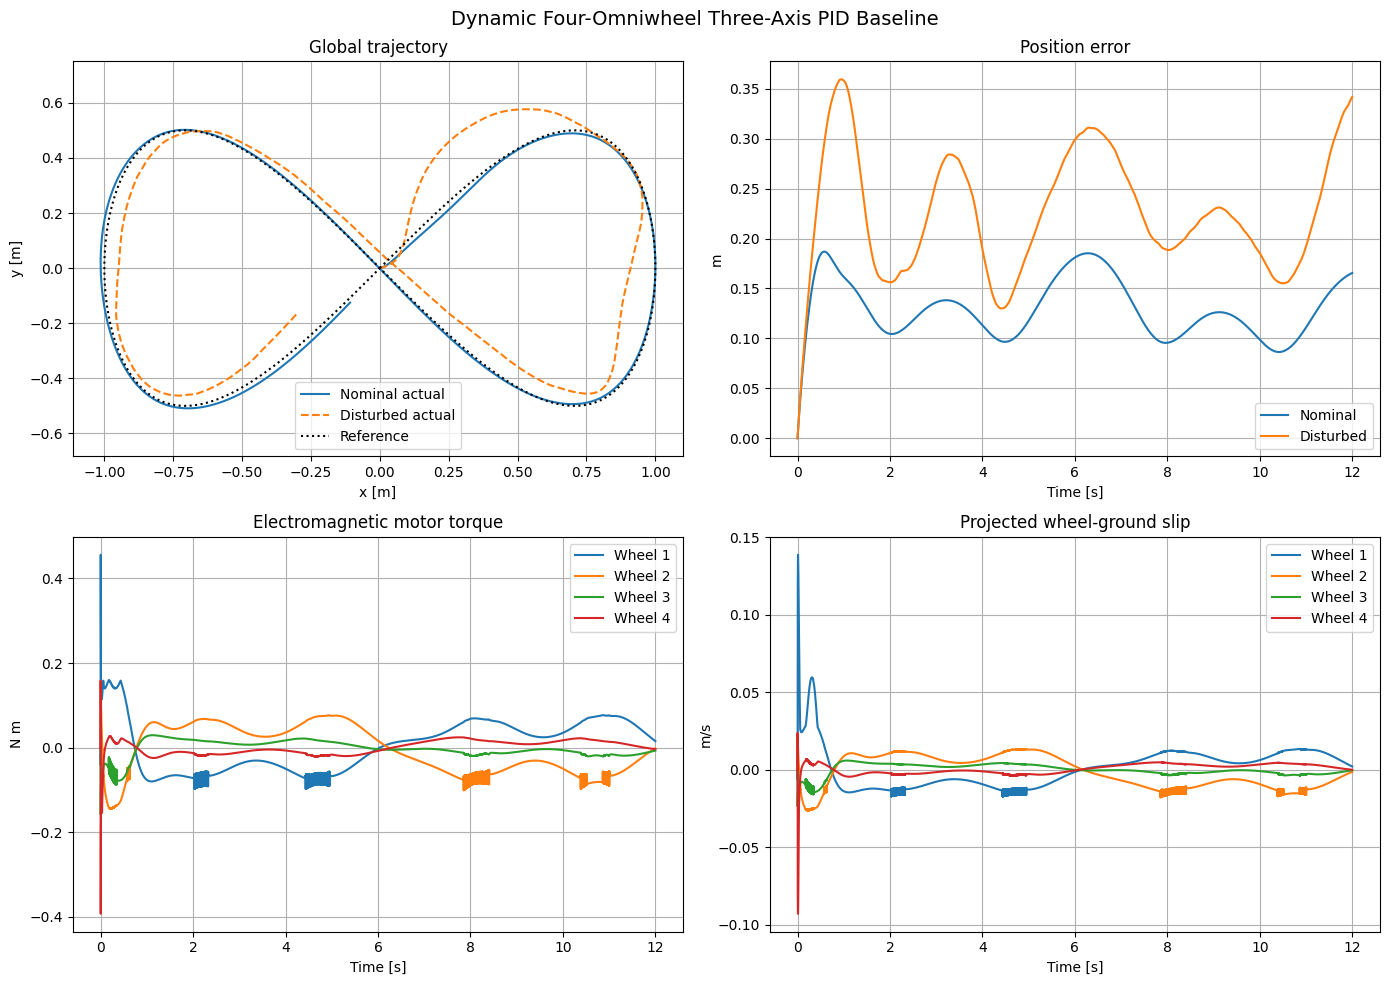

In [9]:
# Run nominal and disturbed conditions with the shared settings from the configuration cell.
DT = SIM_DT_S
PERIOD = REFERENCE_PERIOD_S
DURATION = PERIOD
nominal_result = run_tracking_experiment(period=PERIOD, duration=DURATION, dt=DT, disturbed=False, seed=NOMINAL_RANDOM_SEED)
disturbed_result = run_tracking_experiment(period=PERIOD, duration=DURATION, dt=DT, disturbed=True, seed=NOMINAL_RANDOM_SEED)
summary = {"nominal": summarize_result(nominal_result), "disturbed": summarize_result(disturbed_result)}
print("Dynamic baseline metrics:")
for condition, metrics in summary.items():
    print(f"\n{condition.upper()}")
    for key, value in metrics.items(): print(f"  {key}: {value:.5f}")

# Visualize path tracking, position error, motor torque, and wheel-ground slip.
fig, axs = plt.subplots(2, 2, figsize=PLOT_FIGSIZE_WIDE)
fig.suptitle("Dynamic Four-Omniwheel Three-Axis PID Baseline", fontsize=14)
for result, label, style in [(nominal_result, "Nominal", "-"), (disturbed_result, "Disturbed", "--")]:
    axs[0,0].plot(result["poses"][:,0], result["poses"][:,1], style, label=f"{label} actual")
axs[0,0].plot(nominal_result["references"][:,0], nominal_result["references"][:,1], "k:", label="Reference")
axs[0,0].set(title="Global trajectory", xlabel="x [m]", ylabel="y [m]"); axs[0,0].axis("equal"); axs[0,0].grid(); axs[0,0].legend()
axs[0,1].plot(nominal_result["time"], nominal_result["position_error"], label="Nominal")
axs[0,1].plot(disturbed_result["time"], disturbed_result["position_error"], label="Disturbed")
axs[0,1].set(title="Position error", xlabel="Time [s]", ylabel="m"); axs[0,1].grid(); axs[0,1].legend()
for i in range(4): axs[1,0].plot(nominal_result["time"], nominal_result["motor_torques"][:,i], label=f"Wheel {i+1}")
axs[1,0].set(title="Electromagnetic motor torque", xlabel="Time [s]", ylabel="N m"); axs[1,0].grid(); axs[1,0].legend()
for i in range(4): axs[1,1].plot(nominal_result["time"], nominal_result["slip_speeds"][:,i], label=f"Wheel {i+1}")
axs[1,1].set(title="Projected wheel-ground slip", xlabel="Time [s]", ylabel="m/s"); axs[1,1].grid(); axs[1,1].legend()
plt.tight_layout(); plt.show()


## 9.1 Static-to-kinetic friction transition comparison and slip diagnostics

This paired experiment keeps wheel-ground friction enabled in both runs. It compares:

- **Transition ON:** the effective coefficient blends smoothly from `mu_static` at low slip toward `mu_kinetic` at higher slip.
- **Transition OFF:** the coefficient is held at `mu_static` for all slip speeds. The compliant slip-force law and its force cap remain active.

This switch isolates the effect of the **static-like to kinetic coefficient transition**. It does not remove friction or make the chassis free-floating. Strictly speaking, the code is a regularized friction approximation: the force is still `clip(k_s * slip, ±mu_eff*N)`, so the Coulomb-like force cap remains in both cases.

The plots compare trajectory tracking, position error, per-wheel slip, RMS slip, and contact traction force. High slip does not by itself prove that the force cap is active; interpret slip alongside force and tracking metrics.


Paired friction-transition comparison (traction enabled in both runs):

Static-to-kinetic transition ON
  position_RMSE_m: 0.13210
  position_MAE_m: 0.12879
  position_max_m: 0.18689
  heading_RMSE_rad: 0.65905
  wheel_speed_saturation_fraction: 0.00000
  voltage_saturation_fraction: 0.00000
  current_saturation_fraction: 0.00000
  friction_cap_fraction: 0.00710
  mean_abs_slip_mps: 0.00638

Fixed mu_static (transition OFF)
  position_RMSE_m: 0.13170
  position_MAE_m: 0.12847
  position_max_m: 0.18512
  heading_RMSE_rad: 0.65488
  wheel_speed_saturation_fraction: 0.00000
  voltage_saturation_fraction: 0.00000
  current_saturation_fraction: 0.00000
  friction_cap_fraction: 0.00429
  mean_abs_slip_mps: 0.00618


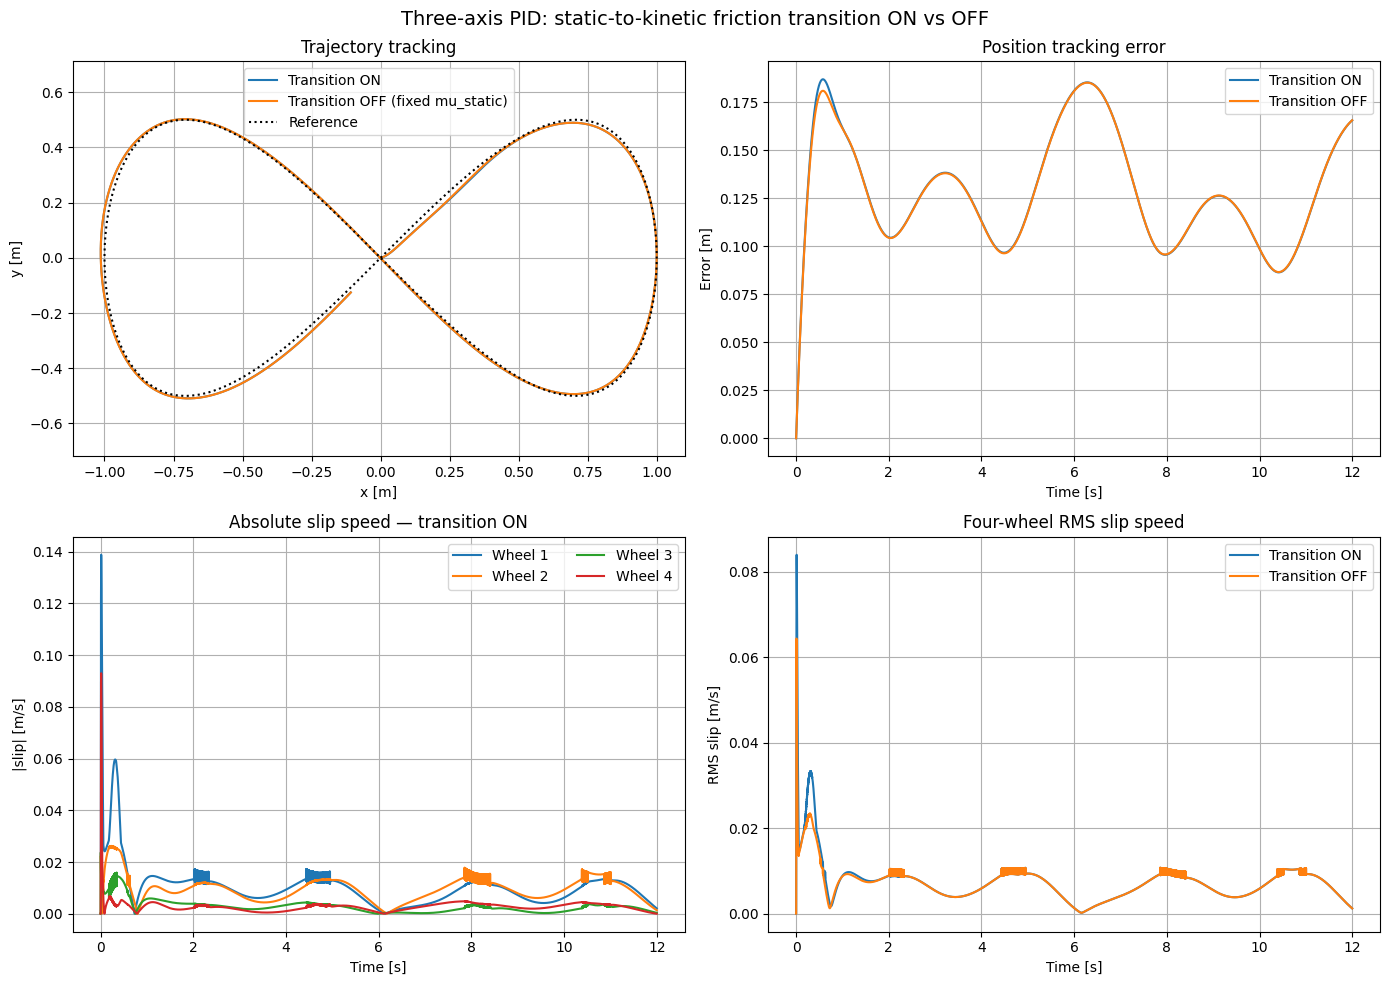

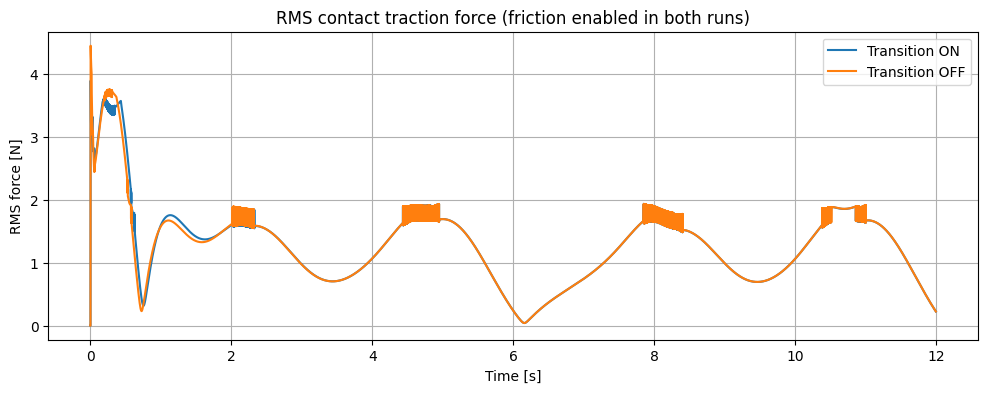

In [10]:
# Paired trial: same seed, path, controller, and physical parameters; only the coefficient transition differs.
comparison_seed = COMPARISON_RANDOM_SEED
transition_on = run_tracking_experiment(period=PERIOD, duration=DURATION, dt=DT,
    disturbed=False, seed=comparison_seed, enable_friction=True,
    enable_static_to_kinetic_transition=True)
transition_off = run_tracking_experiment(period=PERIOD, duration=DURATION, dt=DT,
    disturbed=False, seed=comparison_seed, enable_friction=True,
    enable_static_to_kinetic_transition=False)

comparison_metrics = {
    "Static-to-kinetic transition ON": summarize_result(transition_on),
    "Fixed mu_static (transition OFF)": summarize_result(transition_off),
}
print("Paired friction-transition comparison (traction enabled in both runs):")
for label, metrics in comparison_metrics.items():
    print(f"\n{label}")
    for key, value in metrics.items(): print(f"  {key}: {value:.5f}")

fig, axs = plt.subplots(2, 2, figsize=PLOT_FIGSIZE_WIDE)
fig.suptitle("Three-axis PID: static-to-kinetic friction transition ON vs OFF", fontsize=14)
axs[0,0].plot(transition_on["poses"][:,0], transition_on["poses"][:,1], label="Transition ON")
axs[0,0].plot(transition_off["poses"][:,0], transition_off["poses"][:,1], label="Transition OFF (fixed mu_static)")
axs[0,0].plot(transition_on["references"][:,0], transition_on["references"][:,1], "k:", label="Reference")
axs[0,0].set(title="Trajectory tracking", xlabel="x [m]", ylabel="y [m]"); axs[0,0].axis("equal"); axs[0,0].grid(); axs[0,0].legend()
axs[0,1].plot(transition_on["time"], transition_on["position_error"], label="Transition ON")
axs[0,1].plot(transition_off["time"], transition_off["position_error"], label="Transition OFF")
axs[0,1].set(title="Position tracking error", xlabel="Time [s]", ylabel="Error [m]"); axs[0,1].grid(); axs[0,1].legend()
for i in range(4):
    axs[1,0].plot(transition_on["time"], np.abs(transition_on["slip_speeds"][:,i]), label=f"Wheel {i+1}")
axs[1,0].set(title="Absolute slip speed — transition ON", xlabel="Time [s]", ylabel="|slip| [m/s]"); axs[1,0].grid(); axs[1,0].legend(ncol=2)
slip_rms_on = np.sqrt(np.mean(transition_on["slip_speeds"]**2, axis=1))
slip_rms_off = np.sqrt(np.mean(transition_off["slip_speeds"]**2, axis=1))
axs[1,1].plot(transition_on["time"], slip_rms_on, label="Transition ON")
axs[1,1].plot(transition_off["time"], slip_rms_off, label="Transition OFF")
axs[1,1].set(title="Four-wheel RMS slip speed", xlabel="Time [s]", ylabel="RMS slip [m/s]"); axs[1,1].grid(); axs[1,1].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=PLOT_FIGSIZE_SLIP)
for label, result in [("Transition ON", transition_on), ("Transition OFF", transition_off)]:
    force_rms = np.sqrt(np.mean(result["ground_forces"]**2, axis=1))
    ax.plot(result["time"], force_rms, label=label)
ax.set(title="RMS contact traction force (friction enabled in both runs)", xlabel="Time [s]", ylabel="RMS force [N]"); ax.grid(); ax.legend(); plt.show()


## 9.2 Reference and timestamp checks

Analytic Figure-8 derivatives and state/reference alignment are checked independently of the plant. These tests guard against tracking metrics that compare a state with a reference from a different timestamp.


In [11]:
# Purpose: run the validation or analysis described in the Markdown section immediately above.
def validate_reference(ref: Figure8Reference, dt=REFERENCE_CHECK_DT_S):
    for t in np.linspace(0.13, ref.period-0.17, 11):
        _, vel = ref.pose_velocity(t)
        p_plus, _ = ref.pose_velocity(t+dt); p_minus, _ = ref.pose_velocity(t-dt)
        finite_difference = (p_plus[:2]-p_minus[:2])/(2*dt)
        assert np.allclose(finite_difference, vel[:2], atol=REFERENCE_DERIVATIVE_ATOL, rtol=REFERENCE_DERIVATIVE_ATOL)
    return True
assert validate_reference(Figure8Reference())
assert len(nominal_result["time"]) == len(nominal_result["poses"]) == len(nominal_result["references"])
assert len(nominal_result["position_error"]) == len(nominal_result["time"])
print("PASS: Figure-8 derivatives and timestamp alignment.")


PASS: Figure-8 derivatives and timestamp alignment.


## 9.3 Repeated-seed robustness summary

Friction coefficients are varied once per wheel per trial, while sensor noise is sampled at each observation. Use the same seeds when comparing controllers (paired trials) so differences are not dominated by different friction realizations. This quick summary is not a statistical claim about a physical robot.


In [12]:
# Purpose: Implement or test the subsystem described immediately above.
seed_results = []
# Repeat disturbed trials over a fixed seed set to quantify sensitivity to random disturbances.
for seed in ROBUSTNESS_SEEDS:
    trial = run_tracking_experiment(period=PERIOD, duration=PERIOD, dt=DT, disturbed=True, seed=seed)
    seed_results.append(summarize_result(trial))
rmse_values = np.array([r["position_RMSE_m"] for r in seed_results])
print(f"Disturbed dynamic position RMSE over {len(seed_results)} seeds:")
print(f"  mean = {rmse_values.mean():.5f} m")
print(f"  std  = {rmse_values.std(ddof=1):.5f} m")
print(f"  min  = {rmse_values.min():.5f} m")
print(f"  max  = {rmse_values.max():.5f} m")


Disturbed dynamic position RMSE over 10 seeds:
  mean = 0.23568 m
  std  = 0.00737 m
  min  = 0.22279 m
  max  = 0.24785 m


## 10. Differences from the original uploaded `robot2.ipynb`

**This is the intended comparison:** the original six-code-cell `robot2.ipynb` versus this revised dynamic testbed. The original is executable Python, not just a written specification. It defines `RobotParameters`, `RobotState`, `OmniWheelSimulation`, a PID controller, plotting helpers, and figure-eight tracking experiments. The revised notebook preserves the four-wheel robot / PID tracking goal but changes how actuation, wheel motion, contact, testing, and controller integration are represented.

### Side-by-side comparison

| Area | Original `robot2.ipynb` | Revised dynamic testbed | What changed and why it matters |
|---|---|---|---|
| Notebook organization | Six code cells. The simulation/parameters are in one cell; plotting, PID/reference generation, and multiple runner versions are separate. The path-tracking runner is defined more than once, so later definitions replace earlier ones when cells run in order. | A structured notebook with configuration, model explanation, plant/controller separation, tests, experiments, plots, metrics, limitations, and an LQR plan. | Easier to audit and extend. One shared experiment runner reduces duplicated experiment logic and accidental differences between controller comparisons. |
| Kinematic mapping | Tracking code calls `compute_inverse_kinematics(...)`, but the import that would provide it is commented out and the helper is not defined in the displayed notebook cells. The simulator separately defines wheel rolling directions and wheel positions. | One centralized wheel geometry/Jacobian is used for body-twist-to-wheel-speed mapping and the related velocity/contact calculations. | Reduces sign/geometry drift and makes the command conversion reproducible within the notebook. Wheel order and angle signs still need checking against the actual robot. |
| High-level PID | Computes global pose error, wraps heading error to [-\pi,\pi], rotates translational error into the body frame, applies P/I/D terms, clamps the integral, and clips body velocity outputs. The runner then maps body velocity to wheel-speed targets. | Retains a three-axis pose PID baseline with output limits, and documents the full downstream command chain. The plant is independent of the high-level controller. | The basic PID idea remains; the principal improvement is the actuator/plant interface and the clarity of the control architecture, not a claim that PID itself is newly invented here. |
| Motor torque | Uses `raw_torques = Kt * (u_wheel_speeds - current_omega)` and clips it with a stall-torque/free-speed envelope. But `Kt` is documented in N·m/A, while the parenthesized quantity is angular-speed error; this expression is dimensionally inconsistent as a physical torque law unless `Kt` is reinterpreted as a speed-error gain with different units. | Uses a simplified DC-motor electrical relation: voltage minus back-EMF gives current through winding resistance, current is limited, and torque is `Kt * current`. | Replaces a speed-error-to-torque shortcut with a physically interpretable voltage/current/torque chain. The simplified motor still needs calibrated resistance, torque/back-EMF constants, and limits to represent real hardware. |
| Wheel speed dynamics | Computes next wheel speed by independently interpolating from current speed toward the commanded speed: `current_omega + (u_wheel_speeds - current_omega) * min(1, dt*20)`. This does not use motor torque minus contact/load torque and wheel inertia to determine wheel acceleration. | Integrates wheel rotational dynamics using motor torque, wheel inertia, contact reaction torque, and losses. | Wheel speed and ground reaction now influence each other. This matters when a wheel stalls, slips, or is loaded instead of magically following the command trajectory. |
| Ground contact and slip | Calculates drive force as motor torque divided by wheel radius and switches between static and kinetic friction limits based on whether that force exceeds `mu_s * Fz`. It does not calculate slip from wheel-rim velocity minus ground-contact-point velocity. Also, the original `slip_penalty` is computed after the loop using `f_drive` left over from the last wheel, rather than summing a per-wheel penalty. | Calculates wheel-ground slip speed, traction from the contact model, and a per-wheel force cap; logs slip and friction-cap activity. The static-to-kinetic coefficient transition can be toggled separately from friction itself. | The revised contact model responds to relative motion and reports slip more directly. The old penalty bug is avoided by recording per-wheel quantities. This is still a simplified omniwheel contact model, not a roller-resolved tire model. |
| Chassis dynamics | Sums wheel force vectors and their moments, then uses explicit Euler updates for body velocity and pose. | Uses coupled Newton–Euler chassis motion, wheel/contact reaction coupling, and a more carefully structured pose integration. | Preserves the force-and-moment approach while improving the coupling and integration organization. Timestep-convergence tests are still needed; a smaller timestep alone does not prove accuracy. |
| Disturbances and measurements | Randomizes friction coefficients when disturbances are enabled and adds pose noise directly to `pose_next`, so the stored pose is both physical state and noisy measurement. Uses global random draws without a trial seed interface. | Keeps the true plant state separate from noisy observations, uses repeatable seeds, and supports paired/repeated trials with friction variability. | Prevents sensor noise from directly perturbing the simulated physical state and makes comparisons repeatable. Sensor fusion, encoder quantization, delays, and camera dropouts remain outside the model. |
| Motor and system limits | Includes a speed-dependent torque envelope and body-velocity output clipping. Its power estimate uses `abs(torque)/Kt * 12 V`, without deriving current from applied voltage and back-EMF. | Includes body command limits, wheel-speed cutoff, voltage saturation/deadband, current limits, PI anti-windup, and friction-force caps. | Limits make it possible to observe when requested motion cannot be achieved. The values are modeling assumptions until measured from the real actuator/driver. |
| Experiment configuration and metrics | Uses `dt = 0.02 s` (50 Hz), hard-coded gains and parameters in runner cells, and compares clean/disturbed runs and multiple figure-eight periods. There are duplicated runner definitions and inconsistent gain/period choices between them. | Centralizes tunable configuration and uses a shared runner for tracking, telemetry, disturbance trials, and friction-transition ablations. | Reduces hidden configuration differences and makes paired comparisons more defensible. Results still need to be rerun and interpreted under identical settings. |
| LQR / other controllers | The notebook is centered on PID path tracking; it does not implement an LQR gain design. | Includes a planning-only LQR section; the executable baseline remains PID. | LQR is not yet an implemented competitor. The plan describes how to add it through the controller interface without changing the plant. |

### PID command pathway: from pose error to wheel actuation

1. The reference generator provides a desired pose (x^*,y^*,\theta^*) at the current simulation time.
2. The PID controller compares it with the observed pose, wraps heading error, and rotates global position error into the robot body frame.
3. P, I, and D terms are combined; integral clamping and body-twist output limits prevent the controller from accumulating unlimited correction or requesting unbounded speed.
4. The result is a **body-twist command** (v_x,v_y,\omega), not a motor command. Inverse kinematics applies the wheel Jacobian to produce four target angular velocities (\omega_1,\omega_2,\omega_3,\omega_4).
5. For each wheel, the inner speed PI controller compares target and actual wheel speed and requests motor voltage. Voltage is saturated/deadbanded; back-EMF and winding resistance determine current; current limits and the torque constant determine motor torque.
6. Wheel torque accelerates the wheel against inertia, losses, and the opposing contact torque. Contact forces are capped by the friction model and applied to the chassis, creating translational acceleration and yaw moment.
7. The new physical pose is updated, sensor noise is applied to the observation (not the ground truth), and the next PID cycle uses that observation.

The actuator and contact nonlinearities are not decorative. Voltage/current/speed limits exist because power supplies, motor windings, drivers, and thermal constraints are finite; anti-windup exists because a controller cannot force an actuator beyond saturation; friction caps exist because the ground cannot transmit unlimited tangential force. As a result, a body command can be within the PID limits but still be physically unachievable. Logging saturation and slip helps explain tracking error instead of attributing all error to PID tuning.

### What this comparison does—and does not—establish

- The revised notebook corrects the dimensional issue in the original speed-error-to-torque expression, makes wheel speed respond to wheel/contact dynamics, calculates slip from relative wheel/contact motion, fixes the last-wheel-only slip-penalty pattern, separates true state from noisy observations, and centralizes experiment configuration.
- The original notebook already had meaningful components: a PID with heading wrap and integral clamping, a figure-eight reference, a motor torque-speed envelope, Coulomb-like static/kinetic force limiting, rigid-body force/moment calculations, clean/disturbed trials, and speed-period comparisons. These should be credited as retained design elements rather than presented as wholly new.
- The revised model is more physically coupled, but it is still simplified and uncalibrated. Its DC-motor assumptions and chosen constants must be checked against the actual motor, driver, gearing, wheel inertia, geometry, and floor/turf before treating scores as predictions of hardware performance.


## 11. Limitations and next steps

### Included now
- Newton–Euler chassis translation/yaw dynamics with body-frame rotational coupling.
- Wheel rotational inertia and contact reaction torque, coupled to chassis traction forces.
- DC motor back-EMF and winding resistance, PI wheel-speed servo, voltage deadband and bus saturation, current saturation, and hard wheel-speed cutoff.
- Slip-dependent nonlinear friction with an optional smooth static-to-kinetic coefficient transition and a Coulomb-like force cap (both can be compared while traction stays enabled).
- Per-wheel friction uncertainty, observation noise, and logging of torque/current/voltage/force/slip/saturation metrics.
- Shared experiment runner and reproducible seeds.

### Important remaining approximations
- The current actuator is a simplified 12 V DC motor plus wheel-speed PI model, whereas the original upload describes 24 V NEMA 17 stepper motors with current-reference inputs. Treat this as a deliberate approximation until a stepper/driver-specific model is implemented and calibrated.
- Wheel geometry/sign convention still needs CAD/hardware confirmation.
- Electrical dynamics are quasi-steady; no armature inductance, battery sag, switching, motor thermal state, or gearbox compliance.
- Contact is a one-dimensional compliant friction law along each wheel's rolling direction, with equal normal loads. It omits roller-level mechanics, load transfer, lateral scrub, and detailed bristle friction.
- `slip_stiffness`, wheel inertia, motor constants, controller gains, and friction values are illustrative and must be identified or calibrated. The default motor parameters imply 20 A and 2 N m at stall; check these against the selected motor/gearbox and whether values are motor-shaft or wheel-shaft quantities.
- The speed PI is an actuator servo, not the high-level trajectory controller. If the real robot uses direct voltage/current commands, replace the speed servo interface for controller comparisons.
- Explicit integration at `dt=0.001 s` is a starting point. Perform timestep convergence tests (e.g. 1, 0.5, 0.25 ms) and energy/force sanity checks before tuning controllers.

### Recommended next steps
1. Verify wheel direction vectors and motor/gearbox ratios.
2. Calibrate motor electrical constants and speed-loop response from datasheets or step tests.
3. Tune contact stiffness and friction against measured acceleration/slip data; verify normal load assumptions.
4. Add a timestep-convergence test and unit tests for signs, limits, and force/torque balance.
5. Freeze plant parameters and disturbance seeds before comparing PID, LQR, MPC, and robust/adaptive controllers.

**Interpretation rule:** this notebook is now a coupled, nonlinear dynamic testbed, but its parameter values are starting assumptions—not validated hardware parameters.


## 12. Implementation plan: LQR state-feedback controller and saved Riccati solution

> **Planning only:** this section describes the intended implementation. No LQR code, new controller, or saved gain files have been added yet.

### Goal

Add an LQR controller as a separate high-level controller that can be selected through the existing `controller_factory` interface. It should use the robot's estimated/measured state and reference to calculate an optimal body-motion command, while leaving the motor, wheel, contact/friction, and chassis simulation shared with the PID baseline.

The phrase *optimal \(P\) matrix* needs one distinction:

- \(P\) is the positive-semidefinite solution of the Riccati equation. It quantifies the cost-to-go for state deviations.
- \(K\) is the feedback gain calculated from \(P\). **\(K\), not \(P\), is used directly to calculate the control command.**
- There is no single universally optimal \(P\): it depends on the chosen state, input, linearized model, cost weights, and operating point/reference.

### Proposed architecture

```text
Reference pose / nominal reference state
                 |
                 v
      State estimator / pose measurement
                 |
                 v
     Tracking error state: delta_x
                 |
                 v
     LQR feedback: delta_u = -K delta_x
                 |
                 v
       Nominal input + correction
                 |
                 v
      Existing command limits and
       inverse wheel kinematics
                 |
                 v
 Existing wheel-speed PI -> motors -> wheels/contact -> chassis
                 |
                 v
       New measured/estimated state
```

The LQR must use the same plant and experiment runner as PID. Do not create a second plant just for LQR, because that would make controller comparisons less meaningful.

### Step 1 — Define the state and input before deriving LQR

For a first implementation, use an **outer-loop LQR** that commands body twist, preserving the existing wheel-speed PI servo and motor/contact dynamics. Define a tracking-error state using the available pose and velocity signals, for example:

\[
\delta x =
\begin{bmatrix}
e_x & e_y & e_\theta &
\delta v_x & \delta v_y & \delta \omega
\end{bmatrix}^{T}
\]

Here, position error should be expressed in one clearly documented frame (preferably the body frame for consistency with the current controller), heading error must be angle-wrapped, and velocity deviations must be measured relative to the nominal/reference velocity if a moving operating trajectory is used.

The control correction is:

\[
\delta u =
\begin{bmatrix}
\delta v_{x,\mathrm{cmd}} &
\delta v_{y,\mathrm{cmd}} &
\delta \omega_{\mathrm{cmd}}
\end{bmatrix}^{T}
\]

The actual command is the nominal command plus the LQR correction, followed by the existing command limits. If the first version does not use a nominal/reference input, document that it is a local regulation controller and test it around a fixed operating point before attempting moving-path tracking.

**Important modeling decision:** the current plant is nonlinear and contains saturation, friction limits, and a wheel-speed PI servo. A single linear LQR gain is therefore a local approximation, not an exact optimal controller for every state. The first version should linearize the closed-loop actuator/plant around a declared operating point. If it cannot model the wheel servo and actuator response adequately, the alternative is to augment the state with wheel speeds and relevant servo-integrator states and use wheel-voltage commands as the LQR input; that is a larger and more invasive design, so it should not be the first implementation.

### Step 2 — Obtain a linear model

Around the chosen operating point or nominal trajectory, define deviations from the nominal state and input:

\[
\delta x_{k+1} = A\,\delta x_k + B\,\delta u_k
\]

For a continuous-time derivation, use \(\dot{\delta x}=A_c\delta x+B_c\delta u\), then discretize it using the simulation time step before using a discrete controller. Prefer deriving/linearizing the equations or numerically perturbing the existing plant in a controlled, repeatable test; do not guess \(A\) and \(B\) from PID gains.

Validation checks should confirm the matrix shapes, finite entries, controllability of the selected state/input model, and that small perturbations of the nonlinear simulation agree reasonably with the linear model near the operating point. Do this with friction and actuator settings fixed and documented.

### Step 3 — Define and document the LQR cost

Choose positive-semidefinite state-error weights \(Q\) and positive-definite input weights \(R\):

\[
J = \sum_{k=0}^{\infty}
\left(\delta x_k^T Q\,\delta x_k +
\delta u_k^T R\,\delta u_k\right)
\]

- Larger entries in \(Q\) penalize the corresponding state errors more strongly.
- Larger entries in \(R\) penalize larger command corrections more strongly.
- Because position, angle, linear velocity, and angular velocity have different units, choose weights deliberately and document the units/normalization. Do not use arbitrary unscaled identity matrices and call the result physically optimal.
- Keep \(Q\), \(R\), model settings, and tuning rationale in the centralized configuration section.

### Step 4 — Solve the Riccati equation and compute the feedback gain

For a discrete-time model, solve the discrete algebraic Riccati equation (DARE):

\[
P = A^T P A -
A^T P B (R+B^T P B)^{-1}B^T P A + Q
\]

Then calculate:

\[
K = (R+B^T P B)^{-1}B^T P A,
\qquad
\delta u_k=-K\delta x_k
\]

Use a trusted numerical solver rather than implementing an iterative Riccati solver from scratch. Check that \(P\) is finite and approximately symmetric, that its eigenvalues are non-negative within numerical tolerance, and that the closed-loop matrix \(A-BK\) is stable for the discrete model. If these checks fail, do not save or use the gain as if it were valid.

For a continuous-time design, use the continuous algebraic Riccati equation and its matching continuous-time gain formula instead. Do not mix continuous-time \(P,K\) with a discrete-time model.

### Step 5 — Save a reproducible controller artifact

Save the solution as a versioned artifact (for example, an `.npz` file plus a small human-readable metadata file). Include:

- \(P\), \(K\), and the exact \(A,B,Q,R\) matrices used
- state and input ordering, frames, and units
- continuous or discrete formulation and simulation time step
- operating point or nominal trajectory identifier
- wheel geometry, front/rear angles, plant parameter values, friction mode, and actuator settings
- solver method, numerical tolerances, and validation results
- a model/configuration version or hash and date

Loading must validate dimensions and metadata against the active simulation. If the model, timestep, state ordering, or cost weights differ, warn or reject the saved artifact and require recomputation. Never silently apply a gain generated for a different model.

### Step 6 — Use the saved gain in the feedback simulation

At each time step:

1. Read the measured/estimated pose and available velocity state.
2. Form the state deviation relative to the reference/nominal state, wrapping heading error and using the same coordinate frame used for linearization.
3. Compute the feedback correction \(\delta u=-K\delta x\).
4. Add the nominal input if the design is a trajectory-tracking LQR.
5. Apply the existing body-command limits and convert the body twist to wheel-speed targets using the shared inverse kinematics.
6. Pass those targets through the unchanged wheel-speed PI, motor, friction/contact, and chassis plant.
7. Log state error, raw and saturated commands, and whether the controller is operating outside the linearization region.

For a moving Figure-8 reference, plan for a **trajectory-linearized/time-varying LQR** or a gain schedule if one fixed operating-point gain performs poorly. The reference currently provides pose and analytic velocity for validation, but the existing PID deliberately does not use feedforward. LQR tracking should state explicitly whether a nominal reference input is included; do not accidentally pass reference derivatives into the PID baseline.

### Step 7 — Integrate without changing the PID baseline

- Keep the current three-axis PID controller intact as the baseline.
- Add LQR as a second controller implementing the same `reset()` / `compute(...)` interface (or a small documented common interface).
- Select the controller through the existing `controller_factory` argument.
- Keep the same plant parameters, timestep, reference, disturbance settings, and random seeds for paired comparisons.
- Record the loaded gain artifact identifier in each result so a plot or metric can be traced to the exact controller design.

### Step 8 — Validate in stages

1. **Math checks:** matrix dimensions, finite values, \(P\) symmetry/semidefiniteness, DARE residual, and closed-loop stability.
2. **Linear-model check:** compare the linearized model against small perturbations of the nonlinear simulation near the design point.
3. **Fixed-point test:** test small initial deviations before trying the Figure-8 trajectory.
4. **Nominal trajectory:** compare PID and LQR on identical initial conditions and seeds.
5. **Limits and friction:** test command saturation, wheel-speed limits, both friction-coefficient transition settings, and disturbed trials.
6. **Robustness:** repeat over the same seed set and report mean, standard deviation, maximum tracking error, heading error, command saturation, and slip metrics.
7. **Time-step/model sensitivity:** verify that results do not depend excessively on the chosen integration step or a narrowly selected operating point.

### Acceptance criteria

The LQR addition is ready for comparison only when the saved matrices can be reloaded and validated, the feedback command uses the measured state in the documented order, the same plant is used for PID and LQR, and all controller trials are reproducible. Report performance as a comparison on this modeled plant, not as proof of real-robot optimality.

